# Additive Wite Gaussian Noise

## Signal Classification

Signals can be generally classified into different categories. For instance, we distinguish signals with finite energy and finite power (but potentially infinite energy). Signals $x(t)$ with finite energie fulfill the inequality

\begin{equation}
    \int_{- \infty}^{\infty} |x(t)|^2 dt < \infty \; ,
\end{equation}

for signals with finite power 

\begin{equation}
    \lim_{T \to \infty} \frac{1}{2T} \int_{-T}^T |x(t)|^2 dt < \infty 
\end{equation}

holds equivalently. To make this classification more illustrative, we consider some examples. 

* All periodic Signals, e.g. sine and cosine, have finite power but infinte energy.
* Stationary stochastic signals also have finite power but infinte energy.

Moreover, we distinguish analog and digital signals and mixtures of both.

* An analog signal is continuous in time and amplitude.
* A sampled analog signal is discrete in time, but still continuous in amplitude.
* The amplitude quantization of an analog signal makes its amplitudes discrete, but it is still continuous in time.
* A digital signal is discrete in time as well as in amplitute. Digital signals are obtained from analog ones by pulse code modulation (PCM), i.e. sampling and amplitude quantization.

In communications, random disturbance signals are modeled as stochastic processes and usually called noise. In contrast to deterministic signals, they cannot be expressed by analytic functions but need to be represented by their statistical properties. 

* probability density function or probability mass function for discrete amplitudes
* moments like mean, variance etc.
* auto correlation function and power spectral density function.

In the following, we consider a stationary random process whose statistical properties do not change over time. As a special but very important example, the additive white Gaussian noise (AWGN) channel. The information signal $x(t)$ is corrupted by noise $W(t)$ and the received signal becomes 

\begin{equation}
    y(t) = x(t) + w(t)
\end{equation}

An important parameter is the signal-to-noise-ratio (SNR) $\gamma$. For zero-mean signals $x(t)$ and $w(t)$, it is defined to

\begin{equation}
    \gamma = \frac{\sigma_{\cal X}^2}{\sigma_{\cal W}^2}
\end{equation}

and is usually given in the logarithmic scale $10 \log_{10}(\gamma)$ in dB.

Next, we will discuss teh Gaussian amplitude distribution of $n(t)$. Afterwards, we analyze the temporal behavior by looking at the spectral properties. Both, amplitude and spectral domain are independent of each other and need to be considered separately.

## Characterization of Amplituden Distribution

Usually, noise constitutes of many different sources. If they are independent of each other, their superposition results asymptotically in a Gaussian distribution of the amplitudes. This follows from the central limit theorem. Hence, statistically independent noise components $n_i(t)$ with mean $\mu_{{\cal W},i}$ and variance $\sigma_{{\cal W},i}^2$ yield a sum signal

\begin{equation}
     w(t) = \sum_{i=1}^L w_i(t)
\end{equation}

being Gaussian distributed for $L \to \infty$ with mean and variance

\begin{align}
    \mu_{\cal W} &= \sum_{i=1}^L \mu_{{\cal W},i} \\
    \sigma_{\cal W}^2 &= \sum_{i=1}^L \sigma_{{\cal W},i}^2  \; .
\end{align}


For real valued noise, the Gaussian distrution is defined to 

\begin{equation}
    p_{\cal W}(\xi) = \frac{1}{\sqrt{2 \pi \sigma_{\cal W}^2}} 
                      \cdot e^{- \frac{(\xi-\mu_{\cal W})^2}{2 \sigma_{\cal W}^2}} \; .
\end{equation}

For complex valued noise $w(t)=w'(t)+jw''(t)$ it is usually assumed that real and imaginary parts are statistically independent of each other and the overall noise power $\sigma_{\cal W}^2$ is equally distributed among them. Consequently, $\sigma_{{\cal W}'}^2=\sigma_{{\cal W}''}^2=\frac{\sigma_{\cal W}^2}{2}$ holds. For this case, the complex Gaussian distribution becomes

\begin{align}
    p_{\cal W}(\xi) 
    &= p_{{\cal W}'}(\xi') \cdot p_{{\cal W}''}(\xi'') \\
    &= \frac{1}{\sqrt{2 \pi \sigma_{{\cal W}'}^2}} 
       \cdot e^{- \frac{(\xi'-\mu_{{\cal W}'})^2}{2 \sigma_{{\cal W}'}^2}} 
       \cdot \frac{1}{\sqrt{2 \pi \sigma_{{\cal W}''}^2}} 
       \cdot e^{- \frac{(\xi''-\mu_{{\cal W}''})^2}{2 \sigma_{{\cal W}''}^2}}  \\
    &= \frac{1}{\pi \sigma_{\cal W}^2} 
       \cdot e^{- \frac{(\xi'-\mu_{{\cal W}'})^2 + (\xi''-\mu_{{\cal W}''})^2}
                       {\sigma_{\cal W}^2}}  \\
    &= \frac{1}{\pi \sigma_{\cal W}^2} 
       \cdot e^{- \frac{|\xi-\mu_{\cal W}|^2}{\sigma_{\cal W}^2}} \; .
\end{align}

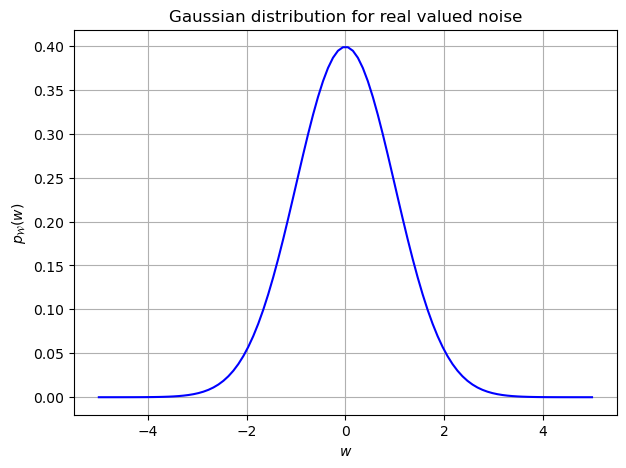

In [4]:
import numpy as np
import matplotlib.pyplot as plt

# real gaussian distribution
# number of samples
N = 100
# variance
sigma2_W = 1.0
# mean
mu_W_real = 0.0
# amplitude range
w_real = 5.0 * np.sqrt(sigma2_W) * np.linspace(-1,1,N) + mu_W_real
pdf_W_real = np.exp(-(w_real-mu_W_real)**2/2/sigma2_W) / np.sqrt(2*np.pi*sigma2_W)

fig_real = plt.figure(figsize=(7,5))

ax1 = fig_real.add_subplot(111)
ax1.plot(w_real, pdf_W_real, 'b-')
plt.xlabel('$w$')
plt.ylabel('$p_{\\cal W}(w)$')
plt.title('Gaussian distribution for real valued noise')
plt.grid(True)

plt.show()

The above figure shows a real valued Gaussian distribution with mean $\mu_{\cal W}=0$ and variance $\sigma_{\cal W}^2=1$. In the figure below, we see the Gaussian distribution for complex valued noise with mean $\mu_{\cal W} = 1+j0.5$ and variance $\sigma_{\cal W}^2=1$. Due to the uniform power distribution onto real and imaginary parts, both have the variance $\sigma_{{\cal W}'}^2=\sigma_{{\cal W}''}^2=0.5$. The associated marginal Gaussian distributions, which are obtained by integration over real or imaginary parts, are also plotted as 2D curves.

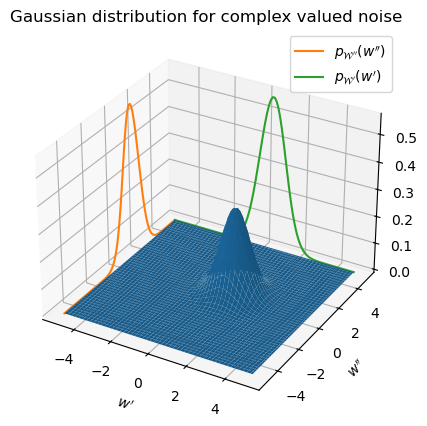

In [5]:
from mpl_toolkits.mplot3d import Axes3D

# complex gaussian distribution
# mean
mu_W_cmplx = 1.0 + 1j*0.5
# amplitude range
dw = w_real[1] - w_real[0]
w_re, w_im = np.meshgrid(w_real,w_real)
w_cmplx = w_re + 1j*w_im
pdf_W_cmplx = np.exp(-np.abs(w_cmplx-mu_W_cmplx)**2/sigma2_W) / (np.pi*sigma2_W)
# marginal densities
pdf_Wi_cmplx = np.sum(pdf_W_cmplx,axis=0) * dw   # imaginary part
pdf_Wr_cmplx = np.sum(pdf_W_cmplx,axis=1) * dw   # real part

fig_cmplx = plt.figure(figsize=(7,5))
ax2 = fig_cmplx.add_subplot(111, projection='3d')
ax2.plot_surface(np.real(w_cmplx),np.imag(w_cmplx), pdf_W_cmplx)
ax2.plot(-np.ones(len(w_real))*5,w_real, pdf_Wi_cmplx,label='$p_{{\\cal W}^{\\prime\\prime}}(w^{\\prime\\prime})$')
ax2.plot(w_real,np.ones(len(w_real))*5, pdf_Wr_cmplx,label='$p_{{\\cal W}^{\\prime}}(w^{\\prime})$')
plt.xlabel('$w^{\\prime}$')
plt.ylabel('$w^{\\prime\\prime}$')
plt.title('Gaussian distribution for complex valued noise')
plt.grid(True)
plt.legend()
plt.show()

## Characterization of temporal behavior

The colouring of the noise describes the temporal behaviour of the signal. White noise contains all spectral components with same intensity similar to white light. Contrarily, coloured noise has frequency depending intensities. The average power distribution in the spectral domain is called power spectral density $S_{\cal WW}(j \omega)$ and has the unit [Watt/Hz]. The total power can be computed via the integral of the power spectral density versus the frequency. For a limited frequency range $[-B/2,+B/2]$, we obtain

\begin{align}
    N = \frac{1}{2 \pi} \cdot \int_{-\pi B}^{\pi B} S_{\cal WW}(j \omega) \ d\omega \; .
\end{align}

For white noise, the power spectral density is constant and is usually defined by $N_0/2$ in the transmission band. In the equivalent baseband, it becomes $N_0$ and is equally distributed onto real and imaginary part. Since the bandwidth is doubled by amplitude modulation, we obtain identical SNRs in the transmission and the equivalent baseband

\begin{align}
    N &= \frac{1}{2 \pi} \cdot \int_{-\pi B}^{\pi B} N_0 \ d\omega 
       = \frac{1}{2 \pi} \cdot \int_{-\omega_0 - \pi B}^{-\omega_0 + \pi B} \frac{N_0}{2}
       \ d\omega 
       + \frac{1}{2 \pi} \cdot \int_{\omega_0 - \pi B}^{\omega_0+\pi B} \frac{N_0}{2} \ d\omega 
      = B N_0 \; .
\end{align}

The temporal behaviour of the noise is coupled with the power spectral density via the famous theorem of Wiener and Khintchine. To be precise, the power spectral density is the Fourier transform of the autocorrelation function.

\begin{equation}
    S_{\cal WW}(j \omega) = \int_{- \infty}^{\infty} r_{\cal WW}(\tau) \ d\tau
\end{equation}

The term $r_{\cal WW}(\tau) = \mathrm{E}\{ w^*(t) w(t-\tau) \}$ represents the autocorrelation function of the noise. White noise can be coloured by linear filtering. 

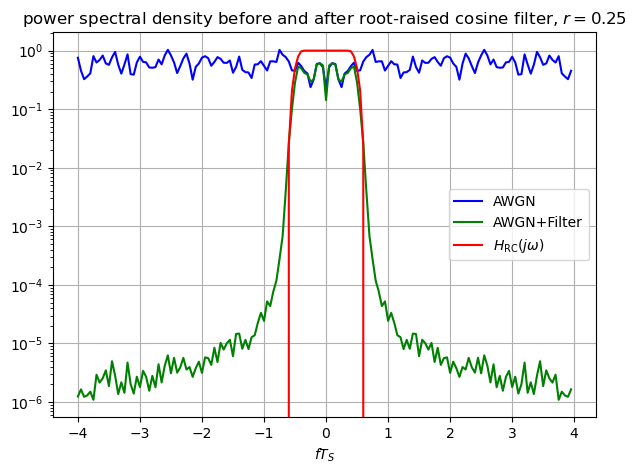

In [7]:
from modulation import rcosfilter, rrcosfilter
from scipy import signal

N = 1000
# averaging for power density spectrum
Npsd = 50

# roll-off factor of Root-Raised-Cosine filter
r = 0.25
# symbol duration in seconds
Ts = 1e-6
# oversampling factor
w = 8
# sampling rate in Hz
fa = w / Ts
# length of filter impulse response in samples
N_rc = 8*w
time,g_rrc = rrcosfilter(N_rc,r,Ts,fa)
time = time / Ts

awgn = np.random.normal(0,sigma2_W,N)

# filter
awgn_rrc = np.convolve(awgn,g_rrc)

# estimation of power spectral density with Welch method
f, psd_awgn = signal.welch(awgn, fs=fa, nperseg=N*w/Npsd, return_onesided=False, scaling='spectrum')
f, psd_awgn_rrc = signal.welch(awgn_rrc, fs=fa, nperseg=N*w/Npsd, return_onesided=False, scaling='spectrum',axis=0)
f = np.fft.fftshift(f)
psd_awgn = np.fft.fftshift(psd_awgn) * N_rc
psd_awgn_rrc = np.fft.fftshift(psd_awgn_rrc)

# analytical solution of power spectral density equals squared magnitude of transfer function of root-raised-cosine transmit filter
# squared magnitude of root-raised-cosine characteristic equals raised-cosine characteristic
# solution normalized to maximum value of 1 (divided by T_s sigma_D^2)
G_RC = 0.5 * (1 + np.cos(np.pi/(2*r)*(np.abs(f)*2*Ts-(1-r))))
ptr = np.argwhere(np.abs(f)*2*Ts<1-r)
G_RC[ptr.flatten()] = 1.0
ptr = np.argwhere(np.abs(f)*2*Ts>1+r)
G_RC[ptr.flatten()] = 0.0

fig = plt.figure(figsize=(7,5))
ax3 = fig.add_subplot(111)
ax3.semilogy(f*Ts, psd_awgn, 'b-', label='AWGN')
ax3.semilogy(f*Ts, psd_awgn_rrc, 'g-', label='AWGN+Filter')
ax3.semilogy(f*Ts, G_RC,'r-',label='$H_{\\mathrm{RC}}(j \\omega)$')
plt.xlabel('$f T_S$')
plt.title('power spectral density before and after root-raised cosine filter, $r=0.25$')
plt.grid(True)
plt.legend()

plt.show()

From the above figure, we clearly see that the originally white noise is colored by the filtering. Its power spectral density equals the squared magnitude of the filter transfer function, filtering with a root-raised-cosine filter results into a raised-cosine characteristic of the power spectral density.